# Multi-Class Road Surface Damage Classification from Images Using Artificial Neural Networks (ANN)

**Pipeline:** data collection → exploration → preprocessing → ANN model → training → evaluation → visual aids.
All figures are saved to the `results/` folder so they can be used in the report and the GitHub repository.

## 1. Setup and libraries

In [1]:
import os, json, random, glob, zipfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
os.makedirs("results", exist_ok=True)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [3]:
%pip install tensorflow

  Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl.metadata (4.5 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached grpcio-1.84.0-cp313-cp313-win_amd64.whl.metadata (3.9 kB)
  Using cached keras-3.15.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached h5py-3.14.0-cp313-cp313-win_amd64.whl.metadata (2.7 kB)
  Using cached ml_dtypes-0.6.0-cp313-cp313-win_amd64.whl.metadata (8.8 kB)
  Using cach

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


## 2. Data collection
Dataset: *Multiclass Road Surface Damage Classification Dataset* (Mendeley Data, DOI page: `data.mendeley.com/datasets/697w4jkr2x`).
Download the ZIP, copy it into the same folder as this notebook, then run the next cell.

In [2]:
ZIP_PATH = "dataset.zip.zip"      
BASE_DIR = "dataset"          

os.makedirs(BASE_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(BASE_DIR)
for inner in glob.glob(BASE_DIR + "/**/*.zip", recursive=True):
    with zipfile.ZipFile(inner) as z:
        z.extractall(os.path.dirname(inner))
print("Extracted to ./" + BASE_DIR)

Extracted to ./dataset


In [3]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")

def find_class_root(base):
    """Find the folder whose sub-folders are the class folders (each holding images)."""
    best, best_n = None, 0
    for dirpath, dirnames, _ in os.walk(base):
        subs = [d for d in dirnames
                if any(f.lower().endswith(IMG_EXT) for f in os.listdir(os.path.join(dirpath, d)))]
        if len(subs) >= 2 and len(subs) > best_n:
            best, best_n = dirpath, len(subs)
    return best

DATA_DIR = find_class_root(BASE_DIR)
print("Class folder root:", DATA_DIR)
counts = {}
for d in sorted(os.listdir(DATA_DIR)):
    p = os.path.join(DATA_DIR, d)
    if os.path.isdir(p):
        counts[d] = sum(f.lower().endswith(IMG_EXT) for f in os.listdir(p))
print(counts, "| total images:", sum(counts.values()))

Class folder root: dataset\Multiclass Road Surface Damage Classification Data\Dataset
{'Crack': 478, 'Pothole': 401, 'Surface Erosion': 651} | total images: 1530


## 3. Data exploration (visual aids)

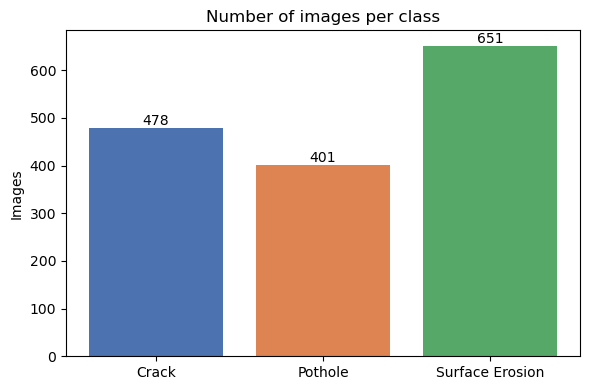

In [4]:
plt.figure(figsize=(6, 4))
bars = plt.bar(counts.keys(), counts.values(), color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"][:len(counts)])
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height(), int(b.get_height()), ha="center", va="bottom")
plt.title("Number of images per class")
plt.ylabel("Images")
plt.tight_layout()
plt.savefig("results/class_distribution.png", dpi=200)
plt.show()

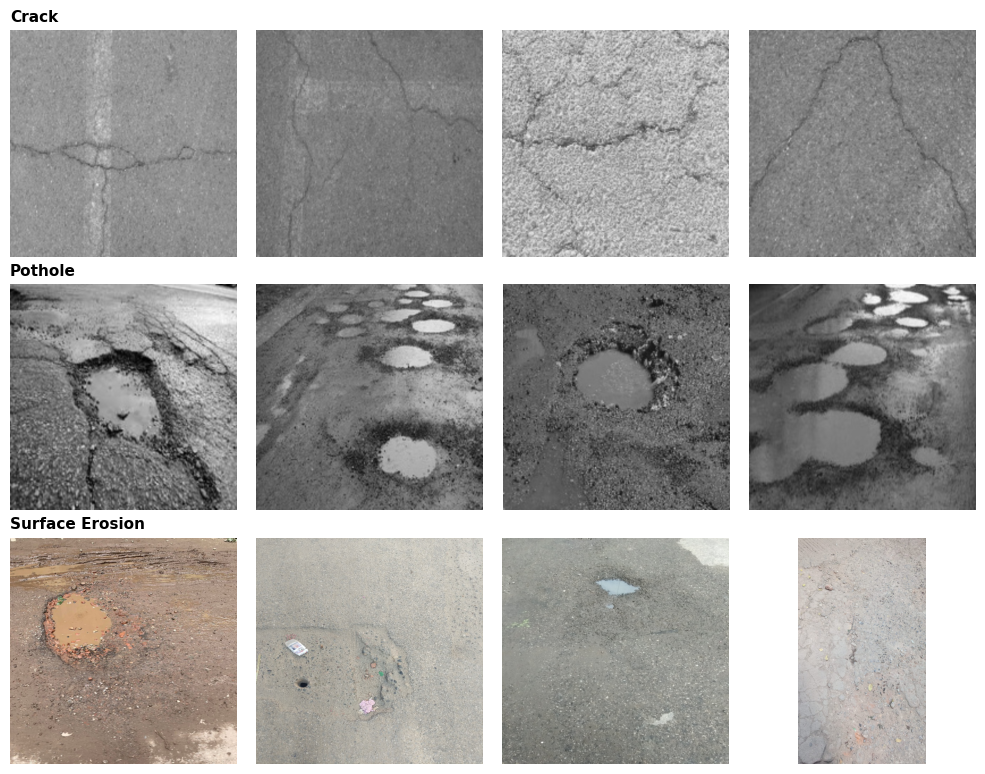

In [5]:
from PIL import Image
classes = [d for d in sorted(os.listdir(DATA_DIR)) if os.path.isdir(os.path.join(DATA_DIR, d))]
fig, axes = plt.subplots(len(classes), 4, figsize=(10, 2.6 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    files_ = [f for f in os.listdir(os.path.join(DATA_DIR, c)) if f.lower().endswith(IMG_EXT)]
    for k, f in enumerate(random.sample(files_, min(4, len(files_)))):
        axes[r, k].imshow(Image.open(os.path.join(DATA_DIR, c, f)).convert("RGB"))
        axes[r, k].axis("off")
        if k == 0:
            axes[r, k].set_title(c, loc="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig("results/sample_images.png", dpi=200)
plt.show()

## 4. Preprocessing: resize, load into arrays, train / validation / test split (70 / 15 / 15, stratified)

In [6]:
IMG_SIZE = 64
raw = keras.utils.image_dataset_from_directory(
    DATA_DIR, image_size=(IMG_SIZE, IMG_SIZE), batch_size=64,
    shuffle=False, label_mode="int")
class_names = raw.class_names
num_classes = len(class_names)
xs, ys = [], []
for xb, yb in raw:
    xs.append(xb.numpy()); ys.append(yb.numpy())
X = np.concatenate(xs).astype("float32")
y = np.concatenate(ys)
print("Classes:", class_names)
print("X shape:", X.shape, "| y shape:", y.shape)

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print("Train:", X_train.shape[0], "| Validation:", X_val.shape[0], "| Test:", X_test.shape[0])

cw = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weights = {int(i): float(w) for i, w in enumerate(cw)}
print("Class weights:", class_weights)

Found 1530 files belonging to 3 classes.
Classes: ['Crack', 'Pothole', 'Surface Erosion']
X shape: (1530, 64, 64, 3) | y shape: (1530,)
Train: 1071 | Validation: 229 | Test: 230
Class weights: {0: 1.0688622754491017, 1: 1.2704626334519573, 2: 0.7828947368421053}


## 5. ANN model (fully connected network on flattened pixels)

In [8]:
model = keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.Rescaling(1.0 / 255),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    layers.Dense(256, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(num_classes, activation="softmax"),
], name="road_damage_ann")

model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()
with open("results/model_summary.txt", "w", encoding="utf-8") as f:
    model.summary(print_fn=lambda s: f.write(s + "\n"))

Model: "road_damage_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)           │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_rotation_1 (RandomRotation)   │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling_1 (Rescaling)              │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 12288)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 512)                 │       6,291,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 512)                 │           2,048 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6,459,651 (24.64 MB)

 Trainable params: 6,458,115 (24.64 MB)

 Non-trainable params: 1,536 (6.00 KB)

## 6. Training

In [9]:
EPOCHS = 60
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, verbose=1),
]
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=EPOCHS, batch_size=32,
                    class_weight=class_weights, callbacks=callbacks, verbose=2)

Epoch 1/60
34/34 - 9s - 269ms/step - accuracy: 0.5378 - loss: 1.1226 - val_accuracy: 0.4236 - val_loss: 12.0527 - learning_rate: 0.0010
Epoch 2/60
34/34 - 3s - 100ms/step - accuracy: 0.5565 - loss: 1.0117 - val_accuracy: 0.4454 - val_loss: 6.8616 - learning_rate: 0.0010
Epoch 3/60
34/34 - 3s - 94ms/step - accuracy: 0.5976 - loss: 0.9413 - val_accuracy: 0.4847 - val_loss: 2.4901 - learning_rate: 0.0010
Epoch 4/60
34/34 - 5s - 151ms/step - accuracy: 0.5845 - loss: 0.9472 - val_accuracy: 0.4017 - val_loss: 3.1987 - learning_rate: 0.0010
Epoch 5/60
34/34 - 3s - 98ms/step - accuracy: 0.6078 - loss: 0.9017 - val_accuracy: 0.4105 - val_loss: 1.4760 - learning_rate: 0.0010
Epoch 6/60
34/34 - 3s - 95ms/step - accuracy: 0.6181 - loss: 0.8795 - val_accuracy: 0.3755 - val_loss: 2.1916 - learning_rate: 0.0010
Epoch 7/60
34/34 - 3s - 97ms/step - accuracy: 0.6218 - loss: 0.8884 - val_accuracy: 0.3712 - val_loss: 2.0580 - learning_rate: 0.0010
Epoch 8/60
34/34 - 3s - 97ms/step - accuracy: 0.6284 - los

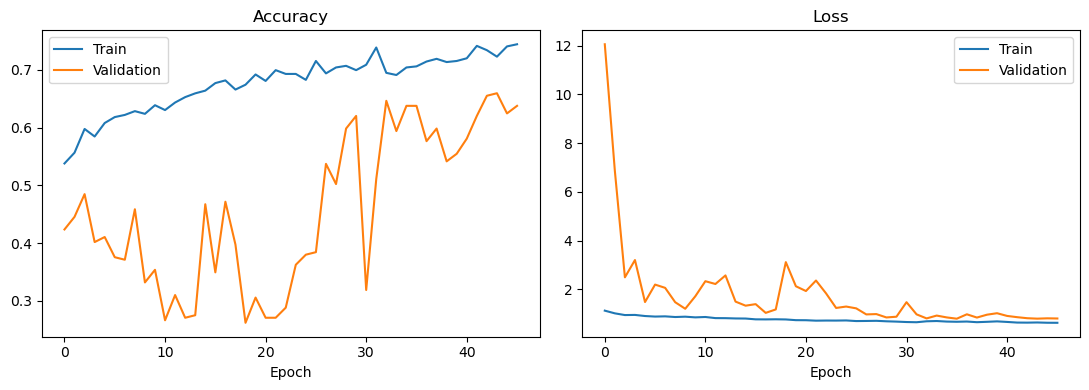

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history["accuracy"], label="Train")
ax[0].plot(history.history["val_accuracy"], label="Validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["loss"], label="Train")
ax[1].plot(history.history["val_loss"], label="Validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout()
plt.savefig("results/training_curves.png", dpi=200)
plt.show()

## 7. Evaluation on the unseen test set

Test accuracy: 0.5739 | Test loss: 0.9104
                 precision    recall  f1-score   support

          Crack       0.49      0.68      0.57        72
        Pothole       0.56      0.45      0.50        60
Surface Erosion       0.67      0.57      0.62        98

       accuracy                           0.57       230
      macro avg       0.58      0.57      0.56       230
   weighted avg       0.59      0.57      0.57       230



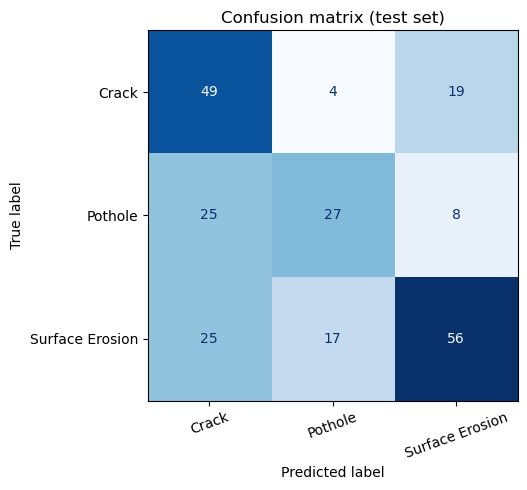

In [11]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}")

y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
report = classification_report(y_test, y_pred, target_names=class_names, output_dict=True, zero_division=0)
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion matrix (test set)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=200)
plt.show()

with open("results/metrics.json", "w") as f:
    json.dump({"test_accuracy": float(test_acc), "test_loss": float(test_loss),
               "classes": class_names, "classification_report": report}, f, indent=2)

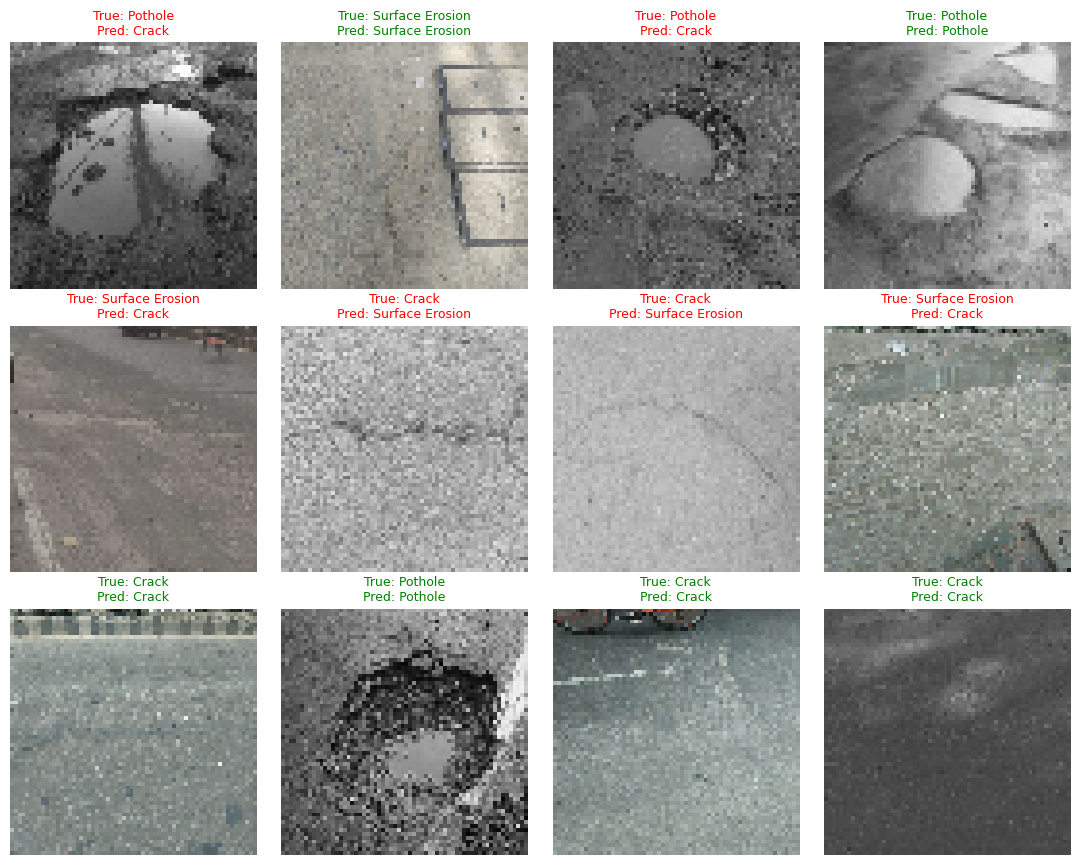

In [12]:
idx = np.random.choice(len(X_test), size=min(12, len(X_test)), replace=False)
cols = 4
rows = int(np.ceil(len(idx) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(11, 2.9 * rows))
for ax, i in zip(np.array(axes).ravel(), idx):
    ax.imshow(X_test[i].astype("uint8"))
    ok = y_pred[i] == y_test[i]
    ax.set_title(f"True: {class_names[y_test[i]]}\nPred: {class_names[y_pred[i]]}",
                 fontsize=9, color="green" if ok else "red")
    ax.axis("off")
for ax in np.array(axes).ravel()[len(idx):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("results/sample_predictions.png", dpi=200)
plt.show()

## 8. Save the model and download all results

In [13]:
model.save("results/road_damage_ann.keras")
print(sorted(os.listdir("results")))

['class_distribution.png', 'confusion_matrix.png', 'metrics.json', 'model_summary.txt', 'road_damage_ann.keras', 'sample_images.png', 'sample_predictions.png', 'training_curves.png']


In [16]:
import shutil
shutil.make_archive("results_bundle", "zip", "results")
print("All results are in the 'results' folder (and results_bundle.zip).")

All results are in the 'results' folder (and results_bundle.zip).
